# 15장 · 함수 명세와 모델의 도구 호출 요청 읽기

‘주말에 도서관이 몇 시까지 열어요?’라는 질문에 모델이 함수를 불러 달라고 답했습니다. 아직 운영 시간을 알아낸 것은 아닙니다. 모델이 볼 수 있는 설명과 실제로 프로그램이 돌려줄 값을 구별해 봅시다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 도구를 부를 때 필요한 칸 읽기

도구 명세에는 함수 이름, 기능 설명, 허용 인자를 적습니다. 수업용 가상 도서관은 day 하나만 받고, 평일이나 주말 중 하나를 고르게 했습니다.

<!-- motion:enum-wheel -->
**도구가 받을 수 있는 요일은 어느 쪽일까요?**

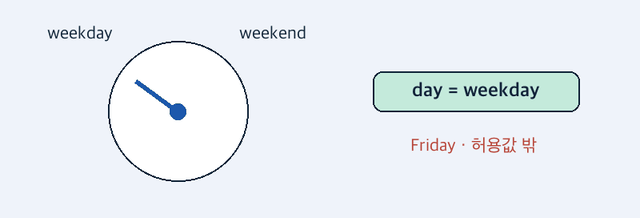

day의 허용값은 weekday와 weekend입니다. 주말 조회에는 weekend가 들어가며, 명세에 없는 Friday는 허용값 밖입니다.
<!-- /motion -->


### 셀 01 · 모델에 전달할 요일 선택지

아래 사전은 함수의 파이썬 본문 없이도 모델에 보낼 수 있는 기능 설명입니다.

In [1]:
import json

TOOL = {
    "type": "function", "name": "get_library_hours",
    "description": "가상 도서관의 요일별 운영 시간을 조회합니다. 실제 예약이나 계정 변경은 하지 않습니다.",
    "parameters": {
        "type": "object",
        "properties": {"day": {"type": "string", "enum": ["weekday", "weekend"]}},
        "required": ["day"], "additionalProperties": False,
    },
    "strict": True,
}

print(TOOL["parameters"]["properties"]["day"]["enum"])

['weekday', 'weekend']


weekday와 weekend가 허용됩니다. 이 명세는 주소나 실제 개관 시간을 제공하지 않습니다. 운영 시간을 조회하는 함수는 다음 장에서 실행합니다.

### 과제 02 · 반드시 넣어야 할 인자 찾기

parameters의 어느 칸에 필수 이름 목록이 있는지 찾아 출력하세요.

In [2]:
# 필수 항목 목록을 꺼내세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>print(TOOL[&quot;parameters&quot;][&quot;required&quot;])</code></pre>
<p>실행 결과</p><pre><code>[&#x27;day&#x27;]</code></pre>
<p>day가 필수입니다. description은 무엇을 조회할지 설명하지만 입력의 필수 여부는 required에서 읽습니다.</p>
</details>

## 응답 속 호출 요청 한 건 풀어 보기

호출 요청의 arguments는 JSON이 적힌 문자열입니다. 프로그램이 함수에 넘기기 전에 내용을 풀고 명세에 맞는지 검사해야 합니다.


### 셀 03 · 주말 조회를 요청한 항목

모델 응답의 모양을 본떠 만든 요청입니다. 호출 ID와 함수명을 그대로 보관합니다.

In [3]:
call = {"type": "function_call", "call_id": "call_demo_1", "name": "get_library_hours",
        "arguments": '{"day":"weekend"}'}
args = json.loads(call["arguments"])
print(args["day"])

weekend


weekend는 확인해 달라고 제안한 인자입니다. 실제 함수가 지금까지 한 번도 실행되지 않았으므로 주말 운영 시간은 아직 모릅니다.

### 셀 04 · 설명 메시지 뒤에서 호출 찾기

응답 목록의 첫 항목은 호출 요청이 아닙니다. type을 기준으로 골라야 합니다.

args는 arguments를 풀어서 읽은 값입니다. 다음 단계에서 어느 요청에 답했는지 찾으려면 name·arguments·call_id가 든 호출 원본도 보관해야 합니다. 여기까지는 요청을 읽었을 뿐, 허용된 함수인지와 요일이 올바른지는 실행 전에 검사합니다.

In [4]:
def inspect_calls(items):
    calls = []
    for item in items:
        if item.get("type") != "function_call":
            continue
        args = json.loads(item["arguments"])
        if not isinstance(args, dict):
            raise ValueError("인자는 JSON 객체여야 합니다.")
        calls.append({"call_id": item["call_id"], "name": item["name"], "arguments": args})
    return calls

items = [{"type": "message", "content": []}, call]
print(inspect_calls(items)[0]["call_id"])

call_demo_1


call_demo_1은 골라낸 요청의 식별자입니다. 결과를 돌려줄 때 이 ID가 있어야 어느 요청에 대한 답인지 연결할 수 있습니다.

## 응답이 글로만 끝난 경우

모델은 도구를 항상 요청하는 것이 아닙니다. 사용자에게 전달할 문장만 담긴 응답이라면 실행할 함수도 없습니다.


### 과제 05 · 호출하지 않은 응답 확인하기

글로만 답한 items를 만들고 inspect_calls에 전달해 보세요.

In [5]:
# type이 message인 항목 하나만 있는 목록을 검사하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>items = [{&quot;type&quot;: &quot;message&quot;, &quot;content&quot;: [{&quot;type&quot;: &quot;output_text&quot;, &quot;text&quot;: &quot;질문을 알려 주세요.&quot;}]}]
print(inspect_calls(items))</code></pre>
<p>실행 결과</p><pre><code>[]</code></pre>
<p>빈 목록은 호출 항목을 찾지 못했다는 뜻입니다. 정상 문장이 있는지, 거절인지, 응답이 미완료였는지는 별도로 응답 상태와 내용을 읽어야 합니다.</p>
</details>

## 돌아보기

함수 이름, call_id, arguments의 day를 각각 한 번 짚어 보세요. 명세에 있는 이름을 보냈다는 기록과 실제 도구의 실행 기록을 나눠 두면 다음 장에서 결과가 빠진 곳을 찾을 수 있습니다.